In [82]:
# import packages
import platform
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import calendar
import matplotlib.pyplot as plt
import pygris
import matplotlib.ticker as ticker
import ipywidgets as widgets
from IPython.display import display, clear_output

ModuleNotFoundError: No module named 'ipywidgets'

In [72]:
# Set Seaborn theme
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette='magma',
    font="Arial",
    rc={
        # Figure
        "figure.figsize": (10, 6),
        "figure.dpi": 120,

        # Background
        "axes.facecolor": "white",
        "figure.facecolor": "white",

        # Grid
        "axes.grid": True,
        "grid.color": "#E6E9EC",
        "grid.linestyle": "-",
        "grid.linewidth": 0.7,

        # Axes
        "axes.edgecolor": "#D5DADF",
        "axes.linewidth": 0.8,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,

        # Ticks
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,

        # Legend
        "legend.frameon": True,
        "legend.fontsize": 7,
        "legend.loc": "upper right",
        "legend.framealpha": 0.9,
        "legend.title_fontsize": 9,
        "legend.edgecolor": "#D5DADF",
        "legend.facecolor": "white",

        # Avoid scientific notation and offset notation
        "axes.formatter.useoffset": False,
        "axes.formatter.limits": (-100, 100),
    }
)

# Set default color cycle
plt.rcParams["axes.prop_cycle"] = plt.cycler(
    color=sns.color_palette('magma')
)

In [6]:
# import cleaned fire dataset

project_fldr = Path.cwd().parents[1]

raw_fldr = project_fldr / 'data' / 'raw'
processed_fldr = project_fldr / 'data' / 'processed'

# read in CSV
fire_shp_25 = gpd.read_file(processed_fldr / "fire_shp_25/fire_shp_25.shp")
fire_shp_25.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 521 entries, 0 to 520
Data columns (total 23 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   YEAR_       521 non-null    float64 
 1   STATE       521 non-null    str     
 2   AGENCY      521 non-null    str     
 3   UNIT_ID     521 non-null    str     
 4   FIRE_NAME   521 non-null    str     
 5   INC_NUM     521 non-null    str     
 6   IRWINID     469 non-null    str     
 7   ALARM_DATE  521 non-null    str     
 8   CONT_DATE   514 non-null    str     
 9   C_METHOD    521 non-null    int32   
 10  CAUSE       521 non-null    int32   
 11  OBJECTIVE   521 non-null    float64 
 12  GIS_ACRES   521 non-null    float64 
 13  COMPLEX_ID  17 non-null     str     
 14  COMPLEX_NA  17 non-null     str     
 15  COMMENTS    120 non-null    str     
 16  FIRE_NUM    0 non-null      object  
 17  Shape_Leng  521 non-null    float64 
 18  Shape_Area  521 non-null    float64 
 19  

In [7]:
fire_shp_25['CAUSE'].value_counts()

CAUSE
14    202
1      98
2      63
10     41
7      30
11     26
9      26
5      22
4      10
8       1
15      1
6       1
Name: count, dtype: int64

In [8]:
# make alarm date column datetime
fire_shp_25['ALARM_DATE'] = pd.to_datetime(fire_shp_25['ALARM_DATE'])
fire_shp_25['CONT_DATE'] = pd.to_datetime(fire_shp_25['CONT_DATE'])
fire_shp_25['Alarm Mo_1'] = pd.Categorical(
    values = fire_shp_25['Alarm Mo_1'],
    categories=calendar.month_abbr[1:]
)

In [19]:
#map cause to code
code_to_cause = {
    1: "Lightning",
    2: "Equipment Use",
    3: "Smoking",
    4: "Campfire",
    5: "Debris",
    6: "Railroad",
    7: "Arson",
    8: "Playing with fire",
    9: "Miscellaneous",
    10: "Vehicle",
    11: "Powerline",
    12: "Firefighter Training",
    13: "Non-Firefighter Training",
    14: "Unknown/Unidentified",
}

fire_shp_25['CAUSE_NAME'] = fire_shp_25['CAUSE'].map(code_to_cause)
fire_shp_25['CAUSE_NAME'].head(10)

0    Unknown/Unidentified
1    Unknown/Unidentified
2               Lightning
3               Lightning
4    Unknown/Unidentified
5    Unknown/Unidentified
6               Lightning
7    Unknown/Unidentified
8               Lightning
9    Unknown/Unidentified
Name: CAUSE_NAME, dtype: str

In [20]:
# Set the "selected" values
alarm_start_date = "2025-01-01" #alarm date dropdown range
alarm_end_date = "2025-12-31"
cont_start_date = "2025-01-01" #containment date dropdown range
cont_end_date = "2025-12-31"
cause = ['Lightning','Unknown/Unidentified']
size = 0

# Subset the data
fire_subset = fire_shp_25.loc[
    (fire_shp_25['ALARM_DATE'] >= alarm_start_date) &  # Start date
    (fire_shp_25['ALARM_DATE'] <= alarm_end_date) &    # End date
    (fire_shp_25['CONT_DATE'] >= cont_start_date) &    # Containment start date
    (fire_shp_25['CONT_DATE'] <= cont_end_date) &      # Containment end date
    (fire_shp_25['CAUSE_NAME'].isin(cause)) &
    (fire_shp_25['Shape_Area'] >= size),  
]

fire_subset.head()


,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,IRWINID,ALARM_DATE,CONT_DATE,C_METHOD,...,COMPLEX_NA,COMMENTS,FIRE_NUM,Shape_Leng,Shape_Area,GlobalID,Alarm Mont,Alarm Mo_1,geometry,CAUSE_NAME
0,2025.0,CA,USF,LPF,GIFFORD,00002181,{08A6358F-8301-4093-9988-E265C8F6F0A9},2025-08-01 00:00:00+00:00,2025-10-14 00:00:00+00:00,3,...,NaN,NaN,None,257388.320379,5.326211e+08,{E87207FF-BD3D-4836-8A89-AD218A20B17E},8.0,Aug,"MULTIPOLYGON (((-35131.146 -302750.005, -35107...",Unknown/Unidentified
1,2025.0,CA,USF,LPF,MADRE,00001817,{1AB682F7-CC0F-4DCE-87A4-FA4A9B67AB05},2025-07-02 00:00:00+00:00,2025-07-26 00:00:00+00:00,7,...,NaN,NaN,None,191846.167384,3.269014e+08,{C59C71E2-F79F-440B-8C84-48058988F3CF},7.0,Jul,"POLYGON ((-4405.284 -313794.721, -4405.483 -31...",Unknown/Unidentified
2,2025.0,CA,USF,SNF,GARNET,00001684,{68B988A1-C190-4F0C-9BEA-A658D389D167},2025-08-24 00:00:00+00:00,2025-10-23 00:00:00+00:00,3,...,NaN,NaN,None,234717.355087,2.428892e+08,{DDD0B278-7655-4F20-829D-FEEEF1DC935F},8.0,Aug,"MULTIPOLYGON (((89617.826 -122364.58, 89614.97...",Lightning
3,2025.0,CA,CDF,FKU,SALT,00018739,{7F4A1474-6439-44F3-8F0D-083DCFD33639},2025-09-02 00:00:00+00:00,2025-09-17 00:00:00+00:00,7,...,NaN,Park incident clipped out per BEU,None,90080.360959,1.034115e+08,{6817A72C-90CF-4CD4-8F26-2B9622F1F140},9.0,Sep,"POLYGON ((-31970.799 -229822.278, -31947.464 -...",Lightning
4,2025.0,CA,CDF,LDF,PALISADES,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07 00:00:00+00:00,2025-01-31 00:00:00+00:00,7,...,NaN,NaN,None,116028.197349,9.489426e+07,{73730F90-5D60-4850-98C2-2431C4284CD7},1.0,Jan,"MULTIPOLYGON (((136696.228 -441776.379, 136683...",Unknown/Unidentified


<class 'matplotlib.axes._axes.Axes'>


/var/folders/h4/qqdfcl3j0mn3nz1pkmthxsvh0000gn/T/ipykernel_3932/691905345.py:2: UserWarning: 
The markers list has fewer values (1) than needed (2) and will cycle, which may produce an uninterpretable plot.
  the_plot = sns.relplot(


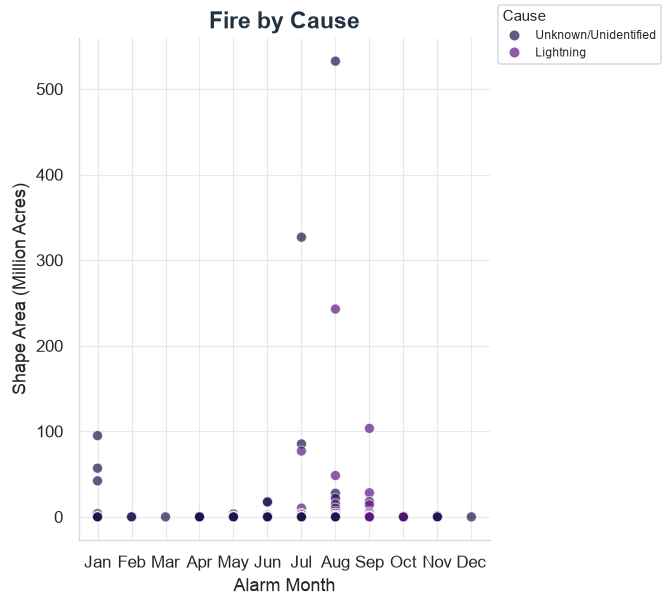

In [77]:

#Create a plot of selected fire by cause
the_plot = sns.relplot(
    data = fire_subset,
    x='Alarm Mo_1',
    y='Shape_Area',
    hue='CAUSE_NAME',
    style='CAUSE_NAME',  markers=['o'],
    alpha=0.7,
    legend = True
)

#Set plot title and axis labels
the_plot.set_axis_labels('Alarm Month', 'Shape Area (Million Acres)')
the_plot.set(title='Fire by Cause')

#Clean up the legend
sns.move_legend(
    the_plot, 
    loc = 'upper right',
    frameon = True,
)

leg = the_plot.legend
leg.get_title().set_ha('left')
leg._legend_box.align = 'left'
leg.get_title().set_text('Cause')


#Set y-axis to use scientific notation
the_plot = plt.gca()
the_plot.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{x/1_000_000:g}')
)

print(type(the_plot))
#Display
the_plot;

In [78]:
### Plot as a function
def plot_fire_cause(alarm_start_date = "2025-01-01", #alarm date dropdown range
                    alarm_end_date = "2025-12-31",
                    cont_start_date = "2025-01-01", #containment date dropdown range
                    cont_end_date = "2025-12-31",
                    cause = ['Lightning','Unknown/Unidentified'],
                    size = 0):
    # Subset the data
    fire_subset = fire_shp_25.loc[
        (fire_shp_25['ALARM_DATE'] >= alarm_start_date) &  # Start date
        (fire_shp_25['ALARM_DATE'] <= alarm_end_date) &    # End date
        (fire_shp_25['CONT_DATE'] >= cont_start_date) &    # Containment start date
        (fire_shp_25['CONT_DATE'] <= cont_end_date) &      # Containment end date
        (fire_shp_25['CAUSE_NAME'].isin(cause)) &
        (fire_shp_25['Shape_Area'] >= size),
        ]   

    #Create a plot of selected fire by cause
    the_plot = sns.relplot(
        data = fire_subset,
        x='Alarm Mo_1',
        y='Shape_Area',
        hue='CAUSE_NAME',
        style='CAUSE_NAME',  markers=['o'],
        alpha=0.7,
        legend = True
    )

    #Set plot title and axis labels
    the_plot.set_axis_labels('Alarm Month', 'Shape Area (Million Acres)')
    the_plot.set(title='Fire by Cause')

    #Clean up the legend
    sns.move_legend(
        the_plot, 
        loc = 'upper right',
        frameon = True,
    )

    leg = the_plot.legend
    leg.get_title().set_ha('left')
    leg._legend_box.align = 'left'
    leg.get_title().set_text('Cause')


    #Set y-axis to use scientific notation
    the_plot = plt.gca()
    the_plot.yaxis.set_major_formatter(
        ticker.FuncFormatter(lambda x, pos: f'{x/1_000_000:g}')
    )

    #return the plot
    return the_plot
    

/var/folders/h4/qqdfcl3j0mn3nz1pkmthxsvh0000gn/T/ipykernel_3932/3083410601.py:19: UserWarning: 
The markers list has fewer values (1) than needed (3) and will cycle, which may produce an uninterpretable plot.
  the_plot = sns.relplot(


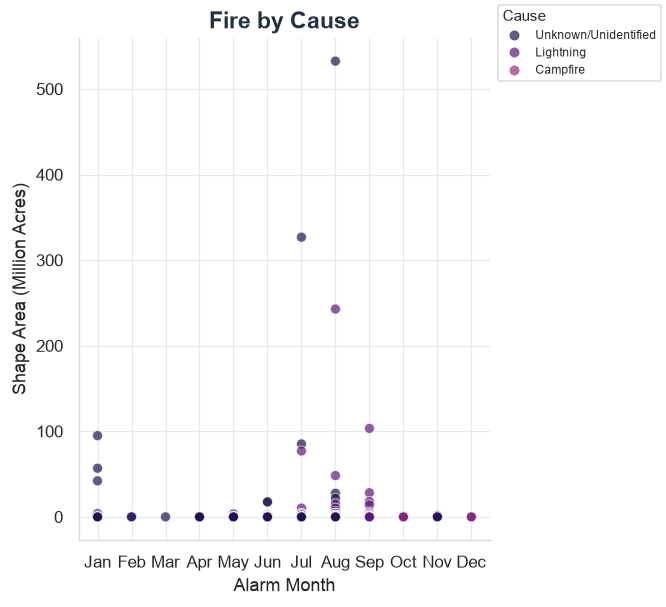

In [79]:
#Apply the function
plot_fire_cause(cause=['Lightning','Unknown/Unidentified','Campfire']);